# Atividade 2 — 3ª etapa

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")

In [2]:
bruto = pd.read_excel("Tabela 1.1.1.xls", sheet_name="2016", header=None, engine="xlrd")

dados = bruto.iloc[8:41].copy()
dados.columns = [
    "uf_regiao", "total", "total_branca", "total_preta_parda",
    "homem_branca", "homem_preta_parda", "mulher_branca", "mulher_preta_parda",
]
dados = dados.reset_index(drop=True)
dados["uf_regiao"] = dados["uf_regiao"].str.strip()
for coluna in dados.columns[1:]:
    dados[coluna] = pd.to_numeric(dados[coluna], errors="raise")

indicador_1 = dados.copy()
if len(indicador_1) != 33 or indicador_1["uf_regiao"].nunique() != 33:
    raise ValueError("A base deve conter Brasil, cinco regiões e 27 UFs, sem duplicatas.")
if indicador_1.isna().any().any():
    raise ValueError("A base contém valores ausentes; confira a aba 2016.")

media_nacional = indicador_1.loc[
    indicador_1["uf_regiao"] == "Brasil", "total"
].item()

## GRÁFICO 1 DE BARRAS

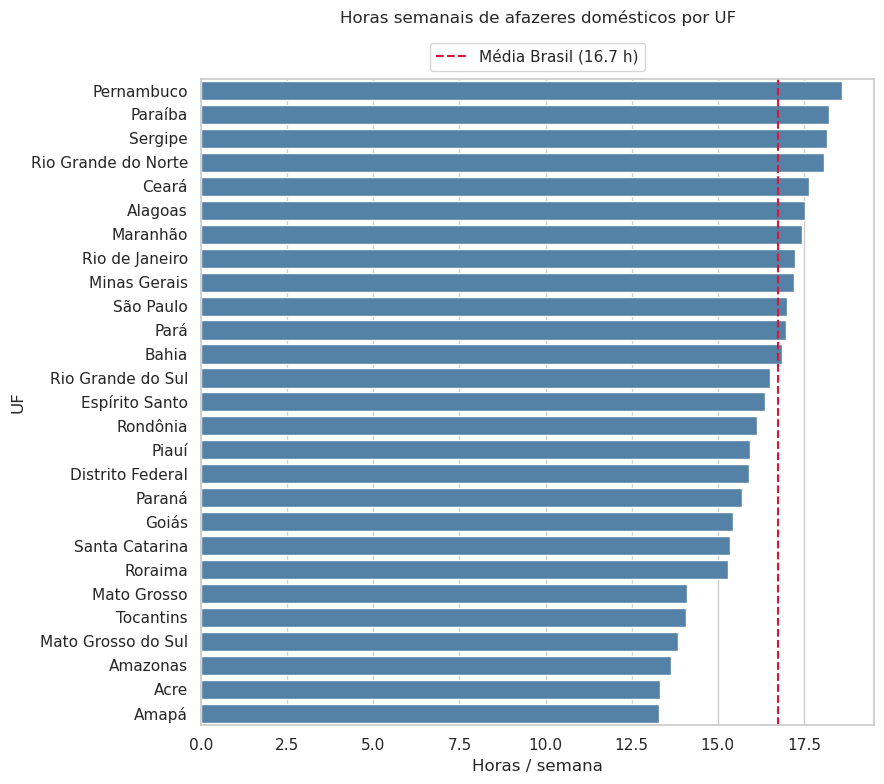

In [3]:
regioes = ["Norte", "Nordeste", "Sudeste", "Sul", "Centro-Oeste"]
estados = indicador_1[~indicador_1["uf_regiao"].isin(["Brasil"] + regioes)].copy()

fig, ax = plt.subplots(figsize=(9, 8))
ordem = estados.sort_values("total", ascending=False)
sns.barplot(data=ordem, y="uf_regiao", x="total", ax=ax, color="steelblue")
ax.axvline(
    media_nacional,
    color="crimson",
    linestyle="--",
    label=f"Média Brasil ({media_nacional:.1f} h)",
)
ax.set_title("Horas semanais de afazeres domésticos por UF", pad=40)
ax.set_xlabel("Horas / semana")
ax.set_ylabel("UF")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0))
plt.tight_layout()
plt.show()

## GRÁFICO 2

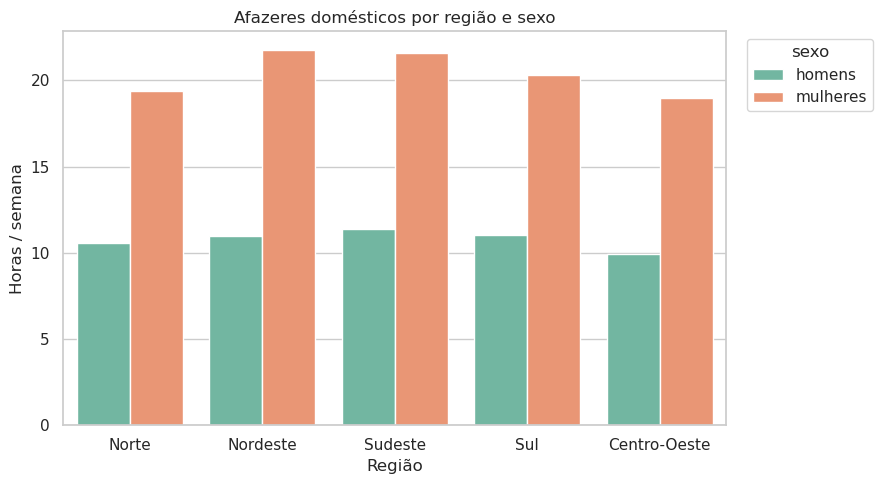

In [4]:
reg = indicador_1[indicador_1["uf_regiao"].isin(regioes)].copy()
reg["homens"] = (reg["homem_branca"] + reg["homem_preta_parda"]) / 2
reg["mulheres"] = (reg["mulher_branca"] + reg["mulher_preta_parda"]) / 2
reg_long = reg.melt(
    id_vars="uf_regiao",
    value_vars=["homens", "mulheres"],
    var_name="sexo",
    value_name="horas",
)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=reg_long, x="uf_regiao", y="horas", hue="sexo", ax=ax)
ax.set_title("Afazeres domésticos por região e sexo")
ax.set_xlabel("Região")
ax.set_ylabel("Horas / semana")
ax.legend(title="sexo", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

## GRÁFICO 3

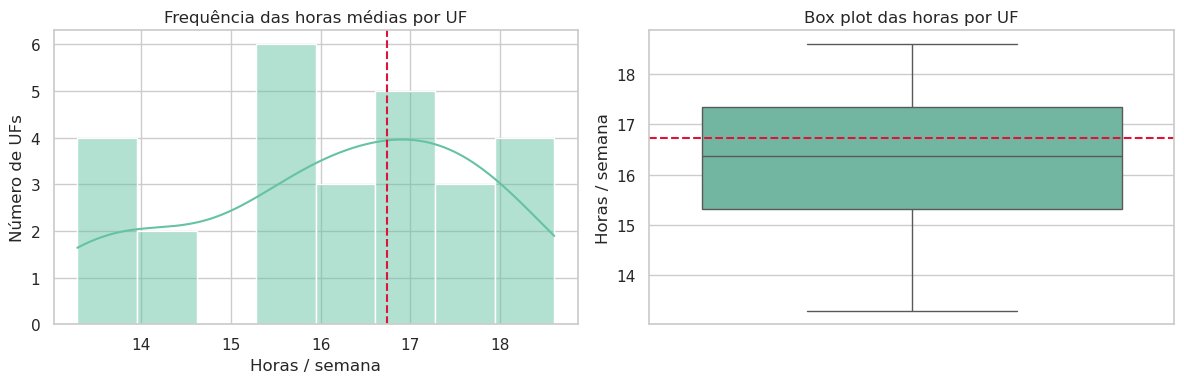

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(estados["total"], bins=8, kde=True, ax=axes[0])
axes[0].axvline(media_nacional, color="crimson", linestyle="--")
axes[0].set_title("Frequência das horas médias por UF")
axes[0].set_xlabel("Horas / semana")
axes[0].set_ylabel("Número de UFs")

sns.boxplot(y=estados["total"], ax=axes[1])
axes[1].axhline(media_nacional, color="crimson", linestyle="--")
axes[1].set_title("Box plot das horas por UF")
axes[1].set_ylabel("Horas / semana")
plt.tight_layout()
plt.show()

## GRÁFICO 4 BOXPLOT

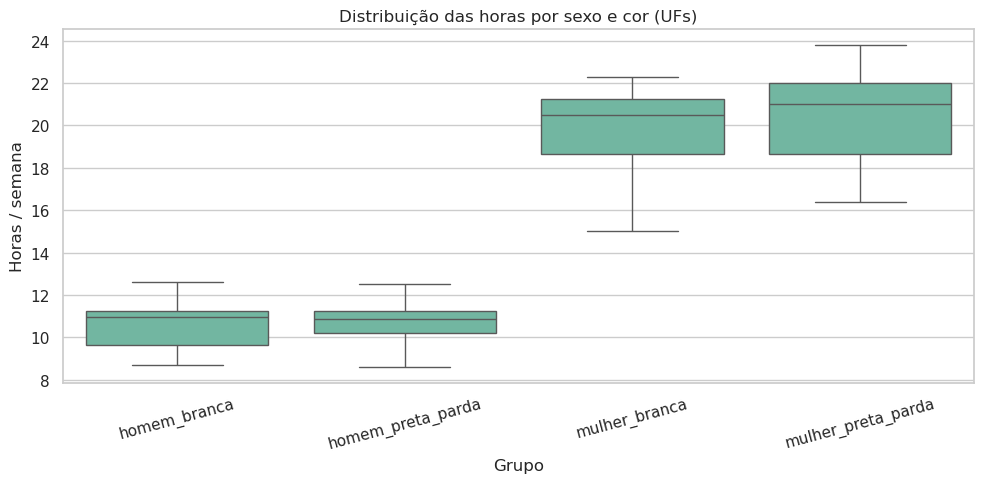

In [6]:
box_df = estados[
    ["homem_branca", "homem_preta_parda", "mulher_branca", "mulher_preta_parda"]
].melt(var_name="grupo", value_name="horas")

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=box_df, x="grupo", y="horas", ax=ax)
ax.set_title("Distribuição das horas por sexo e cor (UFs)")
ax.set_xlabel("Grupo")
ax.set_ylabel("Horas / semana")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()